# 05 · Structural causal model: fitting and diagnostics

**Objective.** Turn a causal graph into a structural causal model (SCM) of the coolant subsystem, fit its mechanisms, and check how well they describe held-out data.

**A graph is not an SCM.** The graph only says *which* variables a variable listens to. The SCM adds *how*: one structural equation per variable.

**Structural equation (binary transition mechanism)**

$$x_j[t] = \mathbb{1}\{U_j[t] < p_j(x_j[t-1],\ \mathrm{pa}_j[t],\ \mathrm{pa}_j[t-1])\},\qquad U_j[t] \sim \mathcal{U}(0,1)$$

- $p_j$ is a conditional probability table. For each previous state and each configuration of the parents' values now and one step earlier, it holds the share of training steps with $x_j[t]=1$, smoothed with a Jeffreys prior (add ½). This is the exact maximum-likelihood family for binary variables. The own previous state captures persistence, which avoids treating autocorrelated time steps as independent.
- Lag-0 parents enter the equations, so the graph must be **acyclic**.

**Assumptions** (stated, not tested by the data)

| Assumption | Meaning here |
|---|---|
| Causal sufficiency | no hidden common causes among the subsystem variables |
| Markov order 1 | the state at t depends on t-1 (own state) and on parents at t and t-1 only |
| Modularity / invariance | an intervention replaces only the intervened variable's equation; all other mechanisms are the same in normal and fault runs. So a variable's mechanism is fitted on all training data **except** runs in which it was manipulated (training-scenario labels only) |
| Unrecorded parents | a parent with no events in a run is set to its usual (training-mode) state |
| Noise model | uniform-threshold noise; needed only for individual counterfactuals (notebook 08) and not identifiable from data |

**Three kinds of question this SCM can answer, with very different evidence behind them**

| Question | Rung | Evidence in this thesis |
|---|---|---|
| What happens next, given what we see? (observational prediction) | association | checked on held-out recordings in this notebook |
| What happens on average if we set X? (population intervention) | intervention | model-predicted; compared with the digital-twin manipulations in notebook 07 |
| What would have happened in *this* run had X been healthy? (individual counterfactual) | counterfactual | model-predicted only; needs the noise assumption (notebook 08) |

In [1]:
import json

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy import stats

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import preprocessing as pp
from causal_rca import scm as sc

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
SUBSYSTEM = 'coolant'
INTERVAL = 0.5
N_REFITS = 10
SEED = 0
rng = np.random.default_rng(SEED)

In [2]:
# data, splits, ground truth for training runs, and the three graphs
view_data, _ = pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}')
tables = data.RESULTS_DIR / 'tables'
splits = pd.read_csv(tables / f'02_{SUBSYSTEM}_splits.csv')
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)
folds = sorted(splits.loc[splits.split == 'fault', 'fold'].unique())

expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
types = {n: ('Alarm' if expert.nodes[n]['kind'] == 'Alarm' else 'Binary') for n in NODES}
edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
discovered_raw = {gid: cd.edges_to_graph(g, NODES) for gid, g in edges.groupby('graph_id')}

dag_logs = []
discovered_dag = {}
for gid, g in discovered_raw.items():
    dag, log = ge.to_dag(g)
    discovered_dag[gid] = dag
    dag_logs.append(log.assign(graph_id=gid))
dag_log = pd.concat(dag_logs, ignore_index=True)
ev.save_table(dag_log, f'05_{SUBSYSTEM}_discovered_dag_log')

empty = nx.DiGraph()
empty.add_nodes_from(NODES)

def graph_for(name, fold=None):
    # graph used by the scm; the discovered graph of a fold never saw that fold
    if name == 'expert':
        return expert
    if name == 'empty':
        return empty
    return discovered_dag['discovered' if fold is None else f'discovered_without_{fold}']

GRAPHS = ['expert', 'discovered', 'empty']
print('edges:', {g: graph_for(g).number_of_edges() for g in GRAPHS})
dag_log[dag_log.graph_id == 'discovered']

edges: {'expert': 10, 'discovered': 6, 'empty': 0}


,source,target,action,graph_id
0,CLF_A_700307,LP_A_700301,dropped (undirected),discovered
1,HP_A_700304,LT_A_700317,dropped (undirected),discovered
2,HP_Pump_Ok,HP_Pump_isOff,dropped (undirected),discovered
3,LT_Level_Ok,LT_Pump_Ok,dropped (undirected),discovered


The discovered graph has to be made acyclic before it can carry an SCM. Undirected edges are **dropped** rather than oriented by guesswork, and any directed cycle is broken by dropping its lowest-support edge. Both are logged above. The empty graph (no parents) is not a competing method: it is the same mechanism family without causal structure, and shows what the graph adds.

## 1. Fitting and mechanism support

In [3]:
# one scm per graph on the full training data: normal training recordings + all fault runs
full_train = data.fold_training_ids(splits, held_out=None)
scms = {g: sc.fit_scm(view_data, graph_for(g), full_train, manipulated, INTERVAL) for g in GRAPHS}
for g, model in scms.items():
    table = sc.mechanism_table(model)
    ev.save_table(table, f'05_{SUBSYSTEM}_mechanisms_{g}')
sc.mechanism_table(scms['expert'])

,variable,parents,has_data,supported,rows_prev0,changes_prev0,configs_seen_prev0,max_switch_prob_prev0,rows_prev1,changes_prev1,configs_seen_prev1,max_switch_prob_prev1
0,CLF_A_700307,CLF_Filter_Ok,True,True,4394,12,3,0.097656,1989,12,3,0.062189
1,CLF_Filter_Ok,,True,False,0,0,0,NaN,136839,0,1,0.000004
2,F_A_700313,F_Filter_Ok,True,True,2231,6,3,0.104839,637,6,3,0.071429
3,F_Filter_Ok,,True,False,0,0,0,NaN,136839,0,1,0.000004
4,HP_A_700304,HP_Pump_Ok,True,True,5610,13,3,0.875000,1803,13,3,0.035714
5,HP_Pump_isOff,"HP_Pump_Ok, LP_Pump_On",True,True,76133,145,5,0.916667,74502,164,7,0.055556
6,HP_Pump_Ok,,True,False,0,0,0,NaN,136839,0,1,0.000004
7,LT_A_700317,LT_Level_Ok,True,True,2817,6,3,0.900000,1170,6,3,0.071429
8,LT_Level_Ok,,True,False,0,0,0,NaN,136839,0,1,0.000004
9,LT_Pump_Ok,LT_Level_Ok,True,True,12136,107,3,0.916667,132205,107,4,0.785714


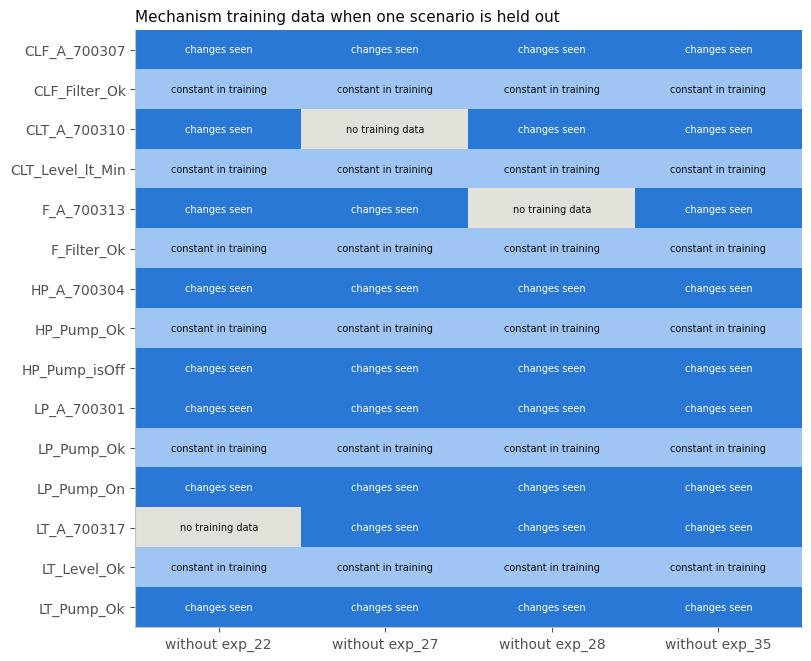

In [4]:
# figure 1: which mechanisms can be learned when one scenario is held out (expert graph)
support_rows = []
fold_scms = {}
for fold in folds:
    train = data.fold_training_ids(splits, fold)
    for g in GRAPHS:
        fold_scms[(g, fold)] = sc.fit_scm(view_data, graph_for(g, fold), train, manipulated, INTERVAL)
    for v, m in fold_scms[('expert', fold)].mechanisms.items():
        support_rows.append({'fold': fold, 'variable': v,
                             'status': 'changes seen' if m.supported else ('constant in training' if m.has_data else 'no training data')})
support = pd.DataFrame(support_rows)
ev.save_table(support, f'05_{SUBSYSTEM}_mechanism_support')
status_code = {'changes seen': 2, 'constant in training': 1, 'no training data': 0}
matrix = support.pivot(index='variable', columns='fold', values='status').reindex(NODES)

fig, ax = plt.subplots(figsize=(8, 6.5), layout='constrained')
colors = [ev.INK['grid'], ev.SEQUENTIAL_BLUE[1], ev.COLORS[0]]
ax.imshow(matrix.apply(lambda col: col.map(status_code)).to_numpy(dtype=float), cmap=ListedColormap(colors), vmin=0, vmax=2, aspect='auto')
for (i, j), s in np.ndenumerate(matrix.to_numpy()):
    ax.text(j, i, s, ha='center', va='center', fontsize=7,
            color=ev.INK['surface'] if s == 'changes seen' else ev.INK['primary'])
ax.set_xticks(range(len(folds)), [f'without {f}' for f in folds])
ax.set_yticks(range(len(NODES)), NODES)
ax.grid(False)
ax.set_title('Mechanism training data when one scenario is held out')
ev.save_figure(fig, f'05_{SUBSYSTEM}_mechanism_support')
plt.show()

**Reading figure 1.**
- *Changes seen*: the mechanism has observed the variable change at least once.
- *Constant in training*: root-cause variables never change outside their own scenario, so their equation says *this variable does not change*. That is exactly what makes a later change surprising (notebook 06).
- *No training data*: the variable was never recorded in any training scenario, for example an alarm that only one scenario records. It has no mechanism estimate for that fold. It is held at its usual state in simulations and marked unsupported.

## 2. Observational fit on held-out normal recordings

In [5]:
# one-step-ahead predictions on the normal validation and test recordings
held_out_normal = splits.loc[splits.split.isin(['validation', 'test']), 'recording_id'].tolist()
normal_pred = {g: sc.held_out_predictions(scms[g], view_data, held_out_normal) for g in GRAPHS}
normal_fit = pd.concat([sc.summarize_predictions(p).assign(graph=g) for g, p in normal_pred.items()], ignore_index=True)
ev.save_table(normal_fit, f'05_{SUBSYSTEM}_fit_normal')
normal_fit[normal_fit.n_changes > 0].pivot(index='variable', columns='graph', values=['log_loss', 'p_observed_change']).round(4)

log_loss                 p_observed_change                
graph         discovered   empty  expert        discovered   empty  expert
variable                                                                  
HP_Pump_isOff     0.0126  0.0168  0.0126            0.0299  0.0021  0.0298
LP_Pump_On        0.0641  0.0641  0.0641            0.0577  0.0577  0.0577
LT_Level_Ok       0.0132  0.0132  0.0132            0.5000  0.5000  0.5000
LT_Pump_Ok        0.0159  0.0159  0.0159            0.0048  0.0048  0.0048

## 3. Mechanism transfer to unseen fault scenarios

For each held-out scenario, the SCM is fitted without it and predicts the scenario's runs one step ahead. The manipulated variables are left out of the evaluation: an intervention replaces their equation, so the fitted equation is not supposed to explain them.

In [6]:
# leave-one-scenario-out one-step-ahead predictions for non-manipulated variables
fault_pred = {g: [] for g in GRAPHS}
for fold in folds:
    test_ids = splits.loc[splits.fold == fold, 'recording_id'].tolist()
    for g in GRAPHS:
        pred = sc.held_out_predictions(fold_scms[(g, fold)], view_data, test_ids, manipulated)
        fault_pred[g].append(pred.assign(fold=fold))
fault_pred = {g: pd.concat(p, ignore_index=True) for g, p in fault_pred.items()}
fault_fit = pd.concat([sc.summarize_predictions(p).assign(graph=g) for g, p in fault_pred.items()], ignore_index=True)
ev.save_table(fault_fit, f'05_{SUBSYSTEM}_fit_unseen_scenarios')
fault_fit[fault_fit.n_changes > 0].pivot(index='variable', columns='graph', values=['change_log_loss', 'p_observed_change']).round(3)

change_log_loss               p_observed_change              
graph              discovered  empty expert        discovered  empty expert
variable                                                                   
CLF_A_700307            2.471  5.423  2.471             0.089  0.005  0.089
CLT_A_700310            0.693  0.693  0.693             0.500  0.500  0.500
F_A_700313              0.693  0.693  0.693             0.500  0.500  0.500
HP_A_700304             1.488  5.244  1.488             0.490  0.010  0.490
HP_Pump_isOff           4.596  6.206  4.618             0.027  0.002  0.027
LP_A_700301             1.503  5.263  1.503             0.402  0.007  0.402
LP_Pump_On              3.669  3.669  3.666             0.057  0.057  0.057
LT_A_700317             0.693  0.693  0.693             0.500  0.500  0.500
LT_Pump_Ok              5.943  5.943  5.956             0.005  0.005  0.005

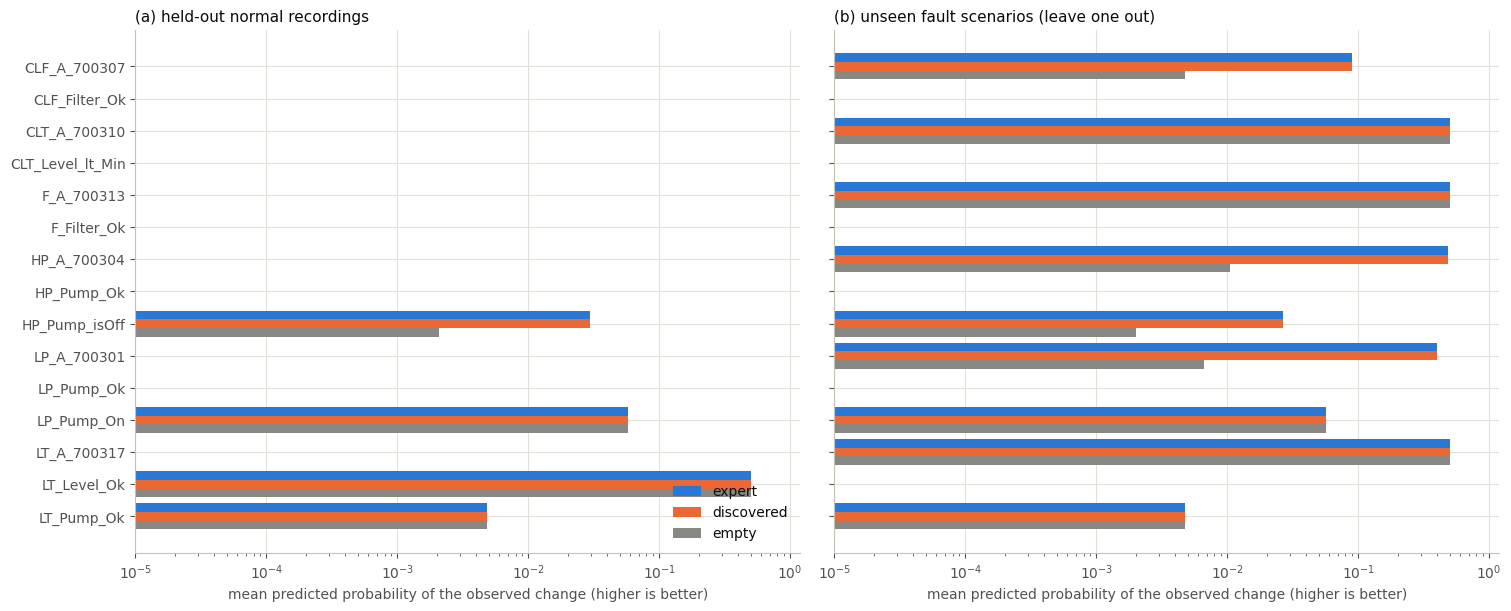

In [7]:
# figure 2: predicted probability of the observed changes, per variable and graph
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True, layout='constrained')
graph_colors = {'expert': ev.COLORS[0], 'discovered': ev.COLORS[1], 'empty': ev.INK['muted']}
for ax, (title, table) in zip(axes, [('(a) held-out normal recordings', normal_fit), ('(b) unseen fault scenarios (leave one out)', fault_fit)]):
    t = table[table.n_changes > 0].pivot(index='variable', columns='graph', values='p_observed_change').reindex(NODES)
    y = np.arange(len(NODES))
    for k, g in enumerate(GRAPHS):
        ax.barh(y + (k - 1) * 0.27, t[g], height=0.27, color=graph_colors[g], label=g)
    ax.set_yticks(y, NODES)
    ax.set_xscale('log')
    ax.set_xlim(1e-5, 1.2)
    ax.set_xlabel('mean predicted probability of the observed change (higher is better)')
    ax.set_title(title)
axes[0].invert_yaxis()
axes[0].legend(loc='lower right')
ev.save_figure(fig, f'05_{SUBSYSTEM}_change_prediction')
plt.show()

**Reading figure 2.** Most steps keep the previous state, so overall log loss is dominated by easy *no change* steps. The informative number is the probability the model gave to the changes that actually happened. A graph helps when a variable's changes are explained by its parents, for example an alarm by its cause. A missing bar means the variable never changes in that data, or (for the leave-one-out panel) that it was manipulated and is therefore not evaluated.

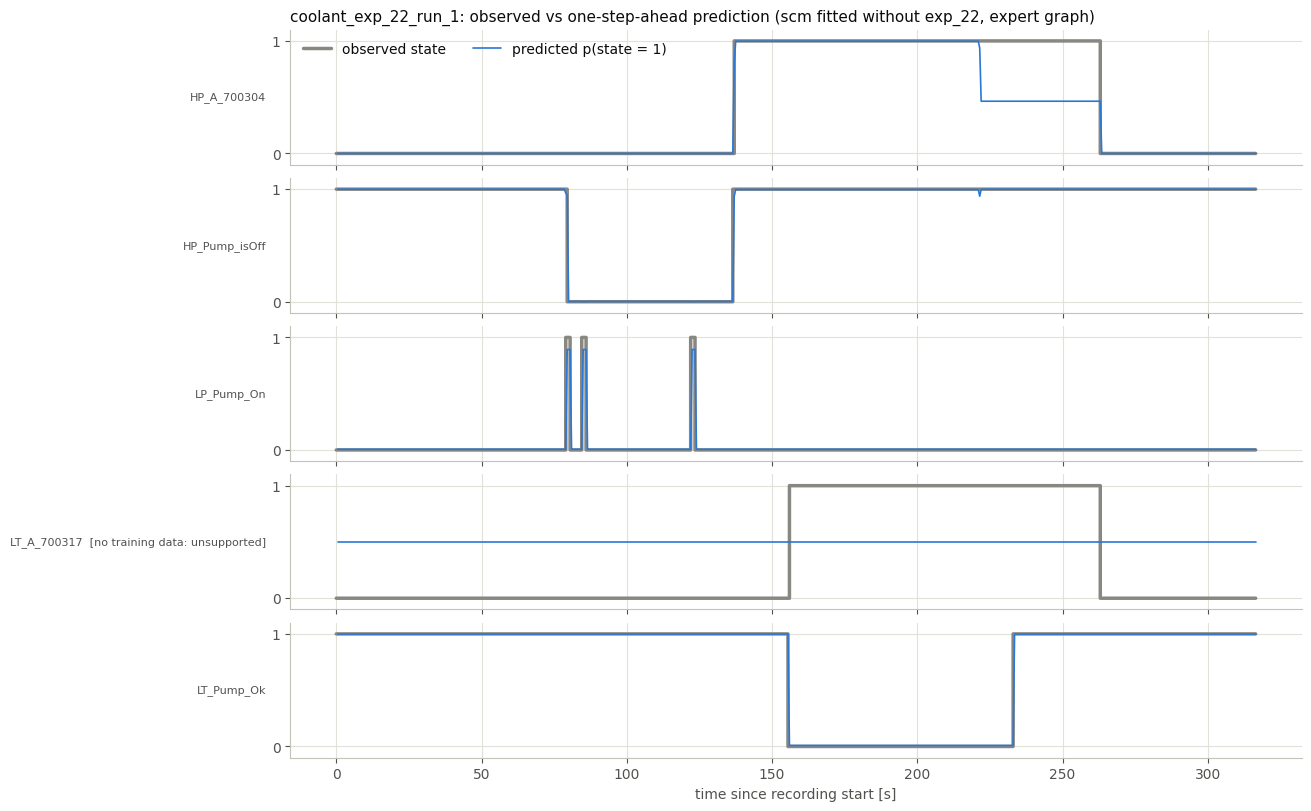

In [8]:
# figure 3: observed states and one-step-ahead predictions in one held-out fault run (expert graph)
example_fold = folds[0]
example_run = splits.loc[splits.fold == example_fold, 'recording_id'].iloc[0]
model = fold_scms[('expert', example_fold)]
series = sc.recording_series(view_data, example_run)
shown = [v for v in NODES if not np.isnan(series[v]).all() and v not in manipulated[example_run]]
t = np.arange(len(series[shown[0]])) * INTERVAL

fig, axes = plt.subplots(len(shown), 1, figsize=(13, 1.4 * len(shown) + 1), sharex=True, layout='constrained')
for ax, v in zip(axes, shown):
    p = model.transition_probs(series, v)
    ax.step(t, series[v], where='post', color=ev.INK['muted'], linewidth=2.5, label='observed state')
    ax.plot(t[1:], p, color=ev.COLORS[0], linewidth=1.2, label='predicted p(state = 1)')
    status = '' if model.mechanisms[v].has_data else '  [no training data: unsupported]'
    ax.set_ylabel(v + status, rotation=0, ha='right', va='center', fontsize=8)
    ax.set_ylim(-0.1, 1.1)
    ax.set_yticks([0, 1])
axes[0].legend(loc='upper left', ncol=2)
axes[-1].set_xlabel('time since recording start [s]')
axes[0].set_title(f'{example_run}: observed vs one-step-ahead prediction (scm fitted without {example_fold}, expert graph)')
ev.save_figure(fig, f'05_{SUBSYSTEM}_observed_vs_predicted')
plt.show()

## 4. Residual diagnostics

Binary outcomes have no ordinary residuals. **Randomized quantile residuals** (Dunn & Smyth) are standard normal when the predicted probabilities are right. A QQ plot against the normal distribution therefore checks calibration of the whole predictive distribution, including the rare changes in the tails.

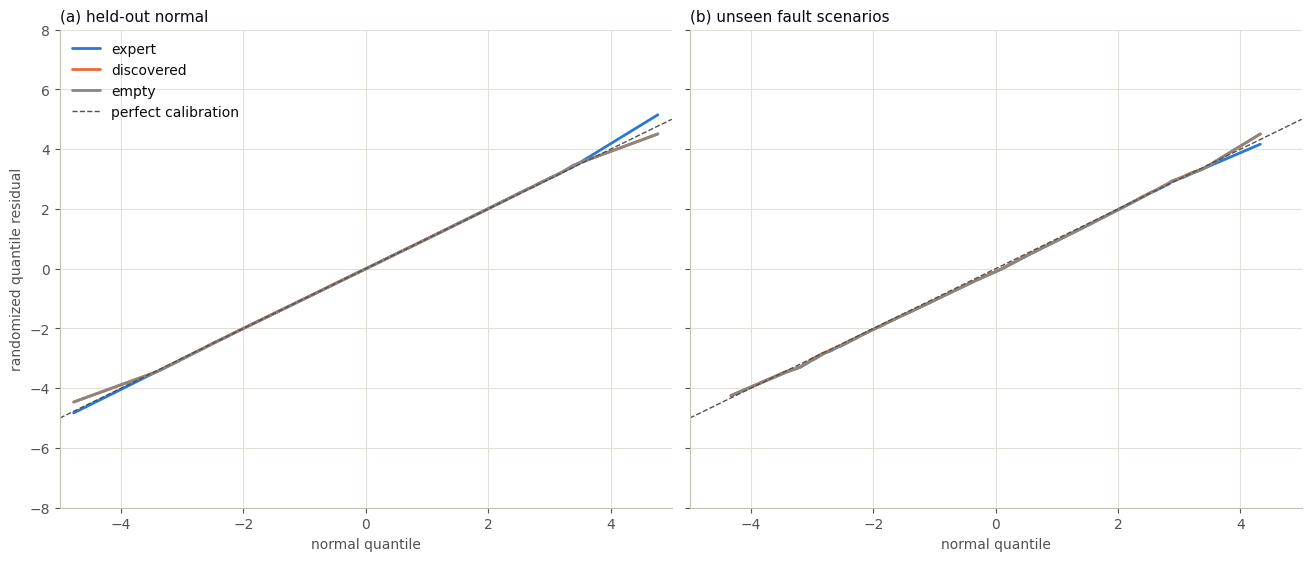

,data,graph,n,mean,std,share_beyond_3
0,(a) held-out normal,expert,549909,-0.0014,1.0017,0.0029
1,(a) held-out normal,discovered,549909,-0.0013,1.0016,0.0029
2,(a) held-out normal,empty,549909,-0.0013,1.0017,0.0029
3,(b) unseen fault scenarios,expert,65554,-0.0650,0.9993,0.0029
4,(b) unseen fault scenarios,discovered,65554,-0.0654,1.0010,0.0030
5,(b) unseen fault scenarios,empty,65554,-0.0708,0.9997,0.0031


In [9]:
# figure 4: qq plots of randomized quantile residuals
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True, layout='constrained')
qq_rows = []
for ax, (title, preds) in zip(axes, [('(a) held-out normal', normal_pred), ('(b) unseen fault scenarios', fault_pred)]):
    for g in GRAPHS:
        r = np.sort(sc.quantile_residuals(preds[g], np.random.default_rng(SEED)))
        q = stats.norm.ppf((np.arange(1, len(r) + 1) - 0.5) / len(r))
        idx = np.unique(np.linspace(0, len(r) - 1, 3000).astype(int))
        ax.plot(q[idx], r[idx], color=graph_colors[g], linewidth=2, label=g)
        qq_rows.append({'data': title, 'graph': g, 'n': len(r), 'mean': r.mean(), 'std': r.std(),
                        'share_beyond_3': float((np.abs(r) > 3).mean())})
    ax.plot([-5, 5], [-5, 5], color=ev.INK['secondary'], linewidth=1, linestyle='--', label='perfect calibration')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-8, 8)
    ax.set_xlabel('normal quantile')
    ax.set_title(title)
axes[0].set_ylabel('randomized quantile residual')
axes[0].legend(loc='upper left')
ev.save_figure(fig, f'05_{SUBSYSTEM}_quantile_residuals')
plt.show()
qq = pd.DataFrame(qq_rows)
ev.save_table(qq, f'05_{SUBSYSTEM}_residual_summary')
qq.round(4)

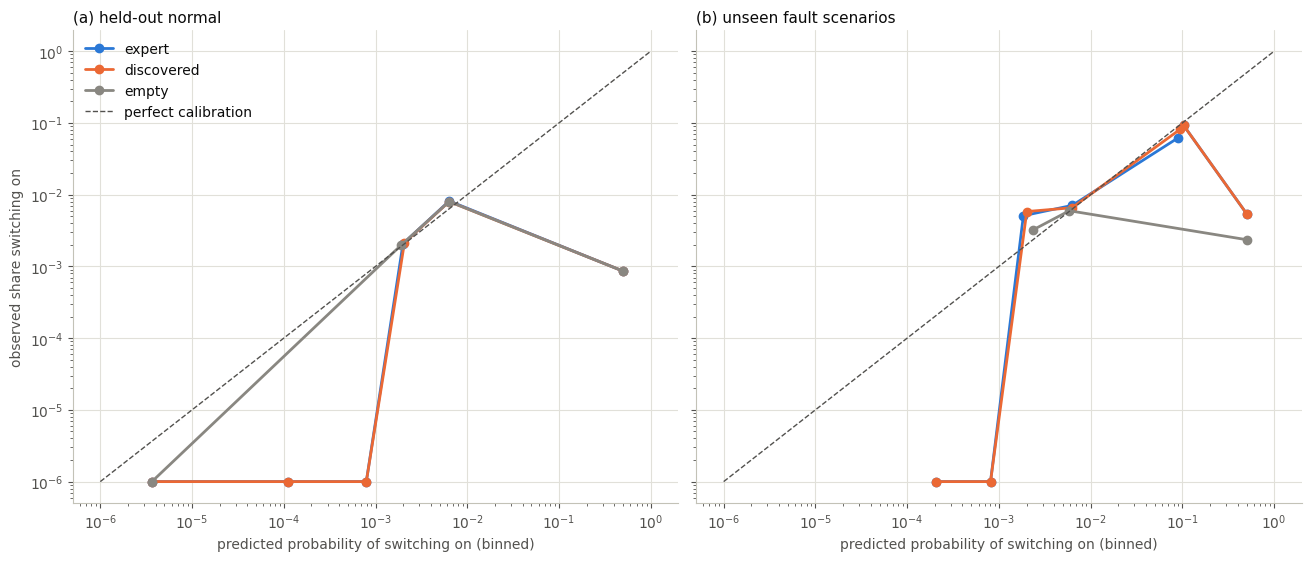

In [10]:
# figure 5: calibration of predicted switching probabilities (rows with x[t-1] = 0, i.e. switch on)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True, layout='constrained')
bins = np.logspace(-6, 0, 13)
for ax, (title, preds) in zip(axes, [('(a) held-out normal', normal_pred), ('(b) unseen fault scenarios', fault_pred)]):
    for g in GRAPHS:
        d = preds[g][preds[g].prev == 0]
        which = np.digitize(d.p, bins)
        grouped = d.groupby(which).agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))
        grouped = grouped[grouped.n >= 20]
        ax.plot(grouped.p, grouped.y.clip(lower=1e-6), marker='o', color=graph_colors[g], label=g)
    ax.plot([1e-6, 1], [1e-6, 1], color=ev.INK['secondary'], linestyle='--', linewidth=1, label='perfect calibration')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('predicted probability of switching on (binned)')
    ax.set_title(title)
axes[0].set_ylabel('observed share switching on')
axes[0].legend(loc='upper left')
ev.save_figure(fig, f'05_{SUBSYSTEM}_calibration')
plt.show()

## 5. Distributional fit: simulated vs observed normal operation

Each held-out normal test recording is re-simulated from its own initial state with fresh noise. If the mechanisms are right, the simulated time spent in state 1 and the simulated switching rate match the observed ones.

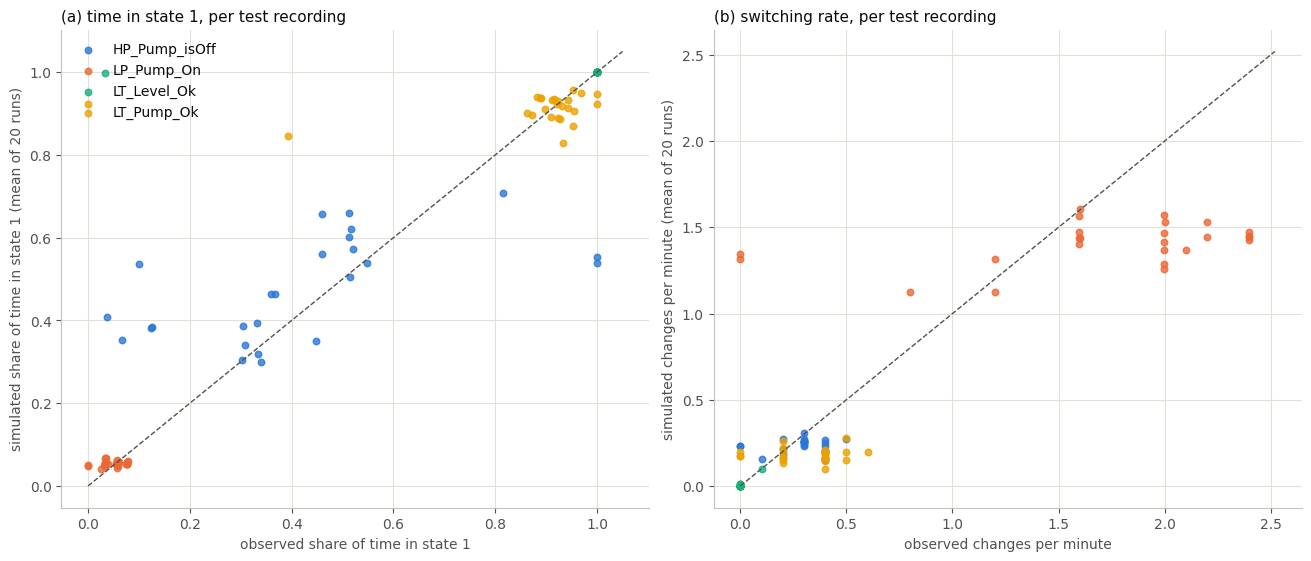

,observed_share_on,simulated_share_on,observed_changes_per_min,simulated_changes_per_min
variable,,,,
HP_Pump_isOff,0.416,0.476,0.296,0.232
LP_Pump_On,0.049,0.054,1.715,1.408
LT_Level_Ok,0.961,1.000,0.004,0.005
LT_Pump_Ok,0.868,0.913,0.316,0.181


In [11]:
# figure 6: simulated vs observed behaviour of the varying variables (expert graph)
test_ids = splits.loc[splits.split == 'test', 'recording_id'].tolist()
behaviour = sc.simulated_behaviour(scms['expert'], view_data, test_ids, np.random.default_rng(SEED), n_samples=20)
ev.save_table(behaviour, f'05_{SUBSYSTEM}_simulated_behaviour')
varying = behaviour.groupby('variable').observed_changes_per_min.sum()
varying = varying[varying > 0].index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
for k, v in enumerate(varying):
    b = behaviour[behaviour.variable == v]
    axes[0].scatter(b.observed_share_on, b.simulated_share_on, s=22, color=ev.COLORS[k % len(ev.COLORS)], label=v, alpha=0.8)
    axes[1].scatter(b.observed_changes_per_min, b.simulated_changes_per_min, s=22, color=ev.COLORS[k % len(ev.COLORS)], label=v, alpha=0.8)
for ax, label in zip(axes, ['share of time in state 1', 'changes per minute']):
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], color=ev.INK['secondary'], linestyle='--', linewidth=1)
    ax.set_xlabel(f'observed {label}')
    ax.set_ylabel(f'simulated {label} (mean of 20 runs)')
axes[0].set_title('(a) time in state 1, per test recording')
axes[1].set_title('(b) switching rate, per test recording')
axes[0].legend(loc='upper left')
ev.save_figure(fig, f'05_{SUBSYSTEM}_simulated_vs_observed')
plt.show()
behaviour[behaviour.variable.isin(varying)].groupby('variable')[['observed_share_on', 'simulated_share_on', 'observed_changes_per_min', 'simulated_changes_per_min']].mean().round(3)

## 6. Mechanism stability

The expert-graph SCM is refitted on bootstrap resamples of the training recordings. Stable mechanisms give similar held-out predictions in every refit.

In [12]:
# refits on resampled training recordings; held-out quality of each refit
refit_rows = []
held_out_all = held_out_normal + splits.loc[splits.split == 'fault', 'recording_id'].tolist()
for b in range(N_REFITS):
    sample = list(rng.choice(full_train, size=len(full_train), replace=True))
    model = sc.fit_scm(view_data, expert, sample, manipulated, INTERVAL)
    summary = sc.summarize_predictions(sc.held_out_predictions(model, view_data, held_out_all, manipulated))
    refit_rows.append(summary.assign(refit=b))
refits = pd.concat(refit_rows, ignore_index=True)
ev.save_table(refits, f'05_{SUBSYSTEM}_refit_stability')
refits[refits.n_changes > 0].groupby('variable').p_observed_change.agg(['mean', 'std', 'min', 'max']).round(4)

,mean,std,min,max
variable,,,,
CLF_A_700307,0.0824,0.0032,0.0798,0.0903
CLT_A_700310,0.2827,0.0140,0.2654,0.3108
F_A_700313,0.0895,0.0036,0.0856,0.0963
HP_A_700304,0.3856,0.0209,0.3616,0.4206
HP_Pump_isOff,0.0505,0.0045,0.0447,0.0587
LP_A_700301,0.4017,0.0110,0.3824,0.4148
LP_Pump_On,0.0597,0.0084,0.0519,0.0722
LT_A_700317,0.3470,0.0245,0.3048,0.3709
LT_Level_Ok,0.5000,0.0000,0.5000,0.5000


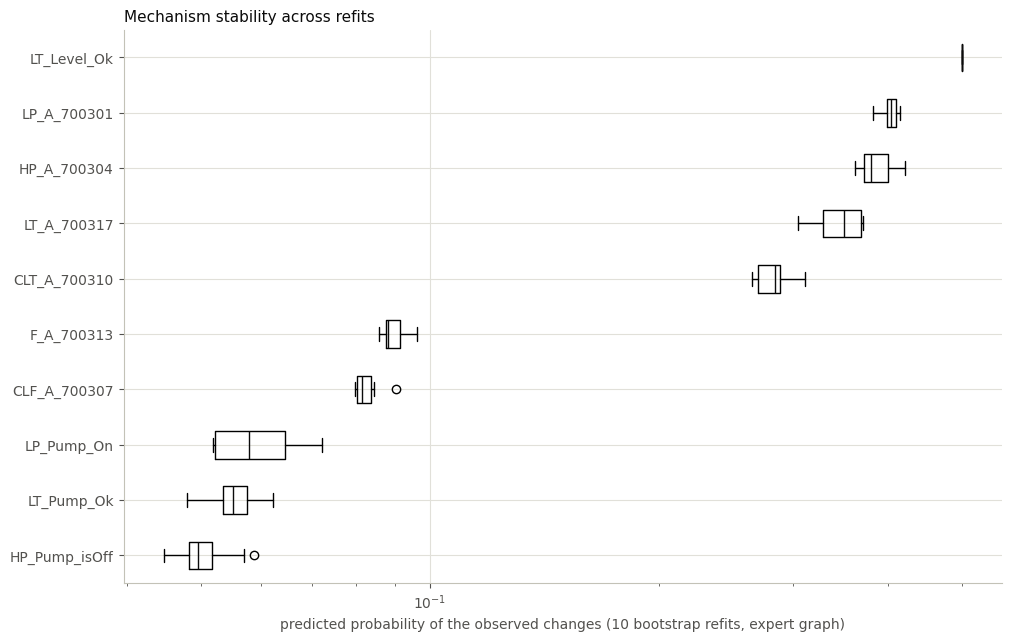

In [13]:
# figure 7: spread of the predicted probability of observed changes across refits
d = refits[refits.n_changes > 0]
order = d.groupby('variable').p_observed_change.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 0.45 * len(order) + 1.8), layout='constrained')
ax.boxplot([d.loc[d.variable == v, 'p_observed_change'] for v in order], vert=False, widths=0.5,
           medianprops={'color': ev.INK['primary']})
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xscale('log')
ax.set_xlabel(f'predicted probability of the observed changes ({N_REFITS} bootstrap refits, expert graph)')
ax.set_title('Mechanism stability across refits')
ev.save_figure(fig, f'05_{SUBSYSTEM}_refit_stability')
plt.show()

## 7. Temporal extension: lag-aware discovered SCM

The first-order mechanisms use every parent now and one step earlier. PCMCI+ found longer lags for three discovered edges (the filter and level alarms), which the first-order SCM cannot represent.

**Model roles.** The first-order SCM is the **primary framework** used throughout the thesis. The **lag-aware SCM** is a **temporal extension**: it adds those lags to the discovered graph only. Both are reported side by side wherever they are compared, with improvements and deteriorations.

**Lag selection.**
- Lags are chosen per fold from the training regimes only, with the aggregation rules of notebook 03:
  - the pair is testable in the regime;
  - the regime found the edge in the same direction as the SCM edge;
  - the lag's share of testable regimes reaches the support threshold.
- Only lags of at least 2 steps are added; lags 0 and 1 are already in every mechanism.
- Opposite-direction lags are excluded and logged. No ±1-step neighbours are added.

**What stays the same.**
- The smoothed probability tables are unchanged.
- The expert, empty and perturbed graphs stay first-order, and the first-order discovered SCM remains the primary model and the baseline.

**Lag history.**
- Fitting skips rows whose lagged values would lie before the recording start.
- Scoring pads such values with the parent's first value. This is a boundary approximation, not recovered history.

**Comparison.** Both models are scored on identical held-out rows: the same recordings, steps and target observations (65,554 rows, of which 6,383 for the filter alarm). Early rows without lag history are included for both; the extension pads them.

In [14]:
# lags per scm graph, from the saved discovery output (no new discovery run)
config = json.loads((data.RESULTS_DIR / 'models' / f'03_{SUBSYSTEM}_discovery_config.json').read_text())
assert config['primary']['apply_fdr_to_graph']
links = pd.read_csv(tables / f'03_{SUBSYSTEM}_links.csv')
relations = cd.regime_relations(links[links.significant])
variables_by_regime = config['variables_by_regime']
threshold = config['primary']['support_threshold']
lag_sets, lag_logs = {}, []
for gid, dag in discovered_dag.items():
    exclude = [] if gid == 'discovered' else [gid.removeprefix('discovered_without_')]
    # the rebuilt static graph must be exactly the saved one
    rebuilt = cd.static_edges(cd.aggregate_relations(relations, variables_by_regime, NODES, threshold, exclude=exclude))
    assert cd.edge_key(rebuilt) == cd.edge_key(edges[edges.graph_id == gid]), gid
    lag_sets[gid], log = cd.edge_lags(relations, variables_by_regime, dag, exclude=exclude, threshold=threshold)
    lag_logs.append(log.assign(graph_id=gid))
lag_log = pd.concat(lag_logs, ignore_index=True)
ev.save_table(lag_log, f'05_{SUBSYSTEM}_lag_selection')
selected = lag_log[lag_log.decision == 'selected']
print('decisions:', lag_log.decision.value_counts().to_dict())
selected.assign(lag_s=selected.lag * INTERVAL).pivot_table(index=['source', 'target'], columns='graph_id', values='lag_s',
                                                           aggfunc=lambda s: ', '.join(f'{x:g}' for x in sorted(s)))

decisions: {'excluded (opposite direction)': 20, 'covered by lag 0/1 terms': 19, 'selected': 16}


,graph_id,discovered,discovered_without_exp_22,discovered_without_exp_27,discovered_without_exp_28,discovered_without_exp_35
source,target,,,,,
CLF_Filter_Ok,CLF_A_700307,"5, 5.5","5, 5.5","5, 5.5",5.5,5
CLT_Level_lt_Min,CLT_A_700310,1,1,NaN,1,1
F_Filter_Ok,F_A_700313,5,5,5,NaN,5


In [15]:
# lag-aware scms: full training data and one per held-out scenario
def lagged_lags(fold=None):
    return lag_sets['discovered' if fold is None else f'discovered_without_{fold}']

lagged_full = sc.fit_scm(view_data, graph_for('discovered'), full_train, manipulated, INTERVAL, lags=lagged_lags())
lagged_fold = {fold: sc.fit_scm(view_data, graph_for('discovered', fold), data.fold_training_ids(splits, fold), manipulated,
                                INTERVAL, lags=lagged_lags(fold)) for fold in folds}
ev.save_table(sc.mechanism_table(lagged_full), f'05_{SUBSYSTEM}_mechanisms_discovered_lagged')
changed = {v for m in lagged_fold.values() for v, mech in m.mechanisms.items() if mech.lags}
print('mechanisms with extra lags:', sorted(changed))
sc.mechanism_table(lagged_full).set_index('variable').loc[sorted(changed),
    ['parents', 'rows_prev0', 'changes_prev0', 'configs_seen_prev0', 'rows_prev1', 'changes_prev1', 'configs_seen_prev1']]

mechanisms with extra lags: ['CLF_A_700307', 'CLT_A_700310', 'F_A_700313']


,parents,rows_prev0,changes_prev0,configs_seen_prev0,rows_prev1,changes_prev1,configs_seen_prev1
variable,,,,,,,
CLF_A_700307,"CLF_Filter_Ok (lags 10, 11)",4274,12,7,1989,12,5
CLT_A_700310,CLT_Level_lt_Min (lags 2),3003,7,4,416,7,4
F_A_700313,F_Filter_Ok (lags 10),2177,6,4,637,6,4


In [16]:
# paired comparison on identical held-out rows: first-order vs lag-aware discovered scm (and the empty graph)
lagged_pred = pd.concat([sc.held_out_predictions(lagged_fold[f], view_data, splits.loc[splits.fold == f, 'recording_id'].tolist(),
                                                 manipulated).assign(fold=f) for f in folds], ignore_index=True)
keys = ['fold', 'recording_id', 'variable', 'step']
paired = (fault_pred['discovered'].merge(lagged_pred, on=keys, suffixes=('_first', '_lagged'))
          .merge(fault_pred['empty'][keys + ['p']].rename(columns={'p': 'p_empty'}), on=keys))
assert len(paired) == len(fault_pred['discovered']) == len(lagged_pred)
assert (paired.y_first == paired.y_lagged).all()
print(f'held-out rows: first-order {len(fault_pred["discovered"])}, lag-aware {len(lagged_pred)}, common {len(paired)} '
      f'(filter alarm {int((paired.variable == "CLF_A_700307").sum())})')
unchanged = paired[~paired.variable.isin(changed)]
print('rows of mechanisms without extra lags whose prediction changed:', int((unchanged.p_first != unchanged.p_lagged).sum()))

def scores(d, p_col):
    p, y = d[p_col].to_numpy(), d.y_first.to_numpy()
    ll = -np.log(np.where(y == 1, p, 1 - p))
    change = y != d.prev_first.to_numpy()
    return pd.Series({'folds': d.fold.nunique(), 'recordings': d.recording_id.nunique(), 'rows': len(d), 'changes': int(change.sum()),
                      'log_loss': ll.mean(), 'change_log_loss': ll[change].mean() if change.any() else np.nan,
                      'brier': np.mean((p - y) ** 2)})

rows = []
for v, d in paired[paired.variable.isin(changed)].groupby('variable'):
    for name, col in [('empty', 'p_empty'), ('discovered (first-order)', 'p_first'), ('discovered + lags', 'p_lagged')]:
        rows.append(scores(d, col).rename(None).to_frame().T.assign(variable=v, model=name))
lag_fit = pd.concat(rows, ignore_index=True)
ev.save_table(lag_fit, f'05_{SUBSYSTEM}_lag_fit_unseen_scenarios')
lag_fit.set_index(['variable', 'model']).round(4)

held-out rows: first-order 65554, lag-aware 65554, common 65554 (filter alarm 6383)
rows of mechanisms without extra lags whose prediction changed: 0


folds  recordings    rows  changes  log_loss  change_log_loss   brier
variable     model                                                                                          
CLF_A_700307 empty                       2.0        12.0  6383.0     24.0    0.0245           5.4228  0.0037
             discovered (first-order)    2.0        12.0  6383.0     24.0    0.0147           2.4715  0.0036
             discovered + lags           2.0        12.0  6383.0     24.0    0.0153           1.7792  0.0041
CLT_A_700310 empty                       1.0         7.0  3426.0     14.0    0.6931           0.6931  0.2500
             discovered (first-order)    1.0         7.0  3426.0     14.0    0.6931           0.6931  0.2500
             discovered + lags           1.0         7.0  3426.0     14.0    0.6931           0.6931  0.2500
F_A_700313   empty                       1.0         6.0  2868.0     12.0    0.6931           0.6931  0.2500
             discovered (first-order)    1.0         6.0  2868.0     12.0    0.6931           0.6931  0.2500
             discovered + lags           1.0         6.0  2868.0     12.0    0.6931           0.6931  0.2500

In [17]:
# per recording and fold: change-row log loss, first-order minus lag-aware (> 0 = lags better), for the evaluable alarm
per_rec = []
for (fold, rid, v), d in paired[paired.variable.isin(changed)].groupby(['fold', 'recording_id', 'variable']):
    s_first, s_lag = scores(d, 'p_first'), scores(d, 'p_lagged')
    if s_first.changes:
        per_rec.append({'fold': fold, 'recording_id': rid, 'variable': v, 'changes': int(s_first.changes),
                        'change_ll_first': s_first.change_log_loss, 'change_ll_lagged': s_lag.change_log_loss,
                        'll_first': s_first.log_loss, 'll_lagged': s_lag.log_loss})
per_rec = pd.DataFrame(per_rec)
per_rec['change_gain'] = per_rec.change_ll_first - per_rec.change_ll_lagged
per_rec['overall_gain'] = per_rec.ll_first - per_rec.ll_lagged
ev.save_table(per_rec, f'05_{SUBSYSTEM}_lag_fit_per_recording')
boot = np.random.default_rng(SEED)
for col in ['change_gain', 'overall_gain']:
    means = [boot.choice(per_rec[col].to_numpy(), len(per_rec)).mean() for _ in range(5000)]
    print(f'{col}: mean {per_rec[col].mean():+.3f}, 95% bootstrap over recordings [{np.quantile(means, 0.025):+.3f}, '
          f'{np.quantile(means, 0.975):+.3f}], recordings better/worse {int((per_rec[col] > 0).sum())}/{int((per_rec[col] < 0).sum())}')
per_rec.groupby(['fold', 'variable'])[['change_ll_first', 'change_ll_lagged', 'll_first', 'll_lagged']].mean().round(4)

change_gain: mean +0.332, 95% bootstrap over recordings [+0.118, +0.588], recordings better/worse 8/4


overall_gain: mean -0.000, 95% bootstrap over recordings [-0.002, +0.001], recordings better/worse 7/5


change_ll_first  change_ll_lagged  ll_first  ll_lagged
fold   variable                                                            
exp_27 CLT_A_700310           0.6931            0.6931    0.6931     0.6931
exp_28 CLF_A_700307           2.2618            1.7401    0.0177     0.0230
       F_A_700313             0.6931            0.6931    0.6931     0.6931
exp_35 CLF_A_700307           2.6812            1.8184    0.0123     0.0091

## 8. Findings

- **The structure carries the alarm mechanisms.** In unseen scenarios, the probability the SCM gives to the alarm changes that actually happened rises with the graph:
  - `HP_A_700304`: 0.010 → 0.49
  - `LP_A_700301`: 0.007 → 0.40
  - `CLF_A_700307`: 0.005 → 0.09 (its 5 s delay is only approximated by one-step lags)

  The discovered graph matches the expert graph on every alarm it contains, because it found the same cause–alarm edges.
- **What no graph can fix.** `CLT_A_700310`, `F_A_700313` and `LT_A_700317` are recorded in only one scenario each. When that scenario is held out, there is no training data for them (p = 0.5, marked unsupported). The coverage pattern of the dataset limits what can be learned, not the method.
- **Weak mechanisms.**
  - `LT_Pump_Ok` (0.005): its expert parent `LT_Level_Ok` changes in only one training recording.
  - `HP_Pump_isOff` (0.03): its changes depend on PLC sequencing that is not in the subsystem graph.

  Both are honest consequences of causal sufficiency being violated or under-sampled.
- **Calibration:**
  - Randomized quantile residuals are close to standard normal (held-out normal: mean −0.001, SD 1.00, 0.29% beyond ±3 vs 0.27% expected).
  - In unseen scenarios the mean is −0.065: the model slightly under-predicts the rare fault-time switches, as expected for transitions it has seen only a few times.
- **Simulation:** simulated normal operation reproduces the time-in-state of the varying variables within about 6 percentage points. Switching rates are somewhat lower than observed (e.g. `LP_Pump_On` 1.41 vs 1.72 per minute), because a first-order model has no memory of the machining cycle.
- **Stability:** bootstrap refits change the predicted probability of observed changes by at most a few hundredths for every mechanism (figure 7).
- **Temporal extension: lag-aware SCM (section 7).** The first-order SCM stays the primary model; both are reported here.
  - **Selected lags**, per fold from training regimes only:
    - `CLF_Filter_Ok → CLF_A_700307`: 5–5.5 s
    - `F_Filter_Ok → F_A_700313`: 5 s
    - `CLT_Level_lt_Min → CLT_A_700310`: 1 s

    20 opposite-direction lags were excluded and logged, and no lag comes from a held-out scenario.
  - **What can be evaluated.** Only `CLF_A_700307` can be evaluated on held-out data: 2 folds, 12 recordings, 6,383 rows, 24 changes. `F_A_700313` and `CLT_A_700310` have no training data when their only scenario is held out, so both models give 0.5 there.
  - **Baseline preserved.** Mechanisms without extra lags give identical predictions (0 rows differ), and every first-order table is unchanged.

  | `CLF_A_700307`, unseen scenarios | Empty graph | First-order | Lag-aware |
  |---|---|---|---|
  | Change-row log loss | 5.42 | 2.47 | 1.78 |
  | Overall log loss | 0.0245 | 0.0147 | 0.0153 |
  | Brier score | 0.0037 | 0.0036 | 0.0041 |

  - **Per recording:** the change-row gain is +0.33 nats [+0.12, +0.59] (better in 8 of 12). Overall log loss is unchanged within noise (−0.000 [−0.002, +0.001]).
  - **The trade-off depends on the fold.**
    - exp_35: both measures improve (overall 0.0123 → 0.0091).
    - exp_28: overall loss rises (0.0177 → 0.0230). The increase sits in long stretches where the alarm keeps its state, away from filter changes.
    - In each fold the alarm table is learned from the 6 runs of the single other scenario, and the extra input splits its cells further. The gain is in timing; the cost is in steady-state calibration.
- *Thesis note:* the SCM is good enough for what follows, i.e. propagating a component fault to its alarm. It is **not** a model of the full machine cycle, and it cannot be: the subsystem graph leaves out the program logic that drives the pumps.